# 03 – Explorative Datenanalyse (EDA)
Nicht-grafische und grafische Analyse der integrierten Daten. Alle Grafiken werden zusätzlich in `outputs/` gespeichert (für die Präsentation).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.db import get_connection

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config.OUTPUT_DIR.mkdir(exist_ok=True)
conn = get_connection()
print("Datenbank:", config.DB_PATH)
from src.features import load_analysis, WOCHENTAGE
df = load_analysis(conn)
print(f"{len(df):,} Ankünfte an {df['bpuic'].nunique()} Bahnhöfen, {df['betriebstag'].nunique()} Tage "
      f"({df['betriebstag'].min()} bis {df['betriebstag'].max()})")

Datenbank: /Users/ayushanahilan/Documents/5. Semester/DataAnalytics/DataAnalytics_Gruppe37/data/zugverspaetung.sqlite


400,135 Ankünfte an 100 Bahnhöfen, 13 Tage (2026-10-14 bis 2026-10-27)


## 1. Nicht-grafische EDA

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400135 entries, 0 to 400134
Data columns (total 29 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   betriebstag          400135 non-null  object        
 1   fahrt_id             400135 non-null  object        
 2   betreiber            400135 non-null  object        
 3   zugtyp               400135 non-null  object        
 4   linie                400135 non-null  object        
 5   bpuic                400135 non-null  int64         
 6   bahnhof              400135 non-null  object        
 7   kanton               400135 non-null  object        
 8   region               400135 non-null  object        
 9   lat                  400135 non-null  float64       
 10  lon                  400135 non-null  float64       
 11  ankunft_soll         400135 non-null  object        
 12  an_delay_min         400135 non-null  float64       
 13  temperatur    

In [3]:
display(df[["an_delay_min", "temperatur", "niederschlag", "schneefall", "wind"]].describe().round(2).T)
display(df.isna().sum().to_frame("fehlende_werte").query("fehlende_werte > 0"))

,count,mean,std,min,25%,50%,75%,max
an_delay_min,400135.0,0.76,2.69,-9.95,-0.23,0.4,1.18,173.15
temperatur,400135.0,10.98,3.67,-0.10,8.60,10.5,13.00,28.20
niederschlag,400135.0,0.20,0.49,0.00,0.00,0.0,0.10,7.50
schneefall,400135.0,0.00,0.02,0.00,0.00,0.0,0.00,1.47
wind,400135.0,6.84,6.25,0.00,2.20,4.5,9.90,35.50


,fehlende_werte


In [4]:
print(f"Anteil verspätet (>= {config.LATE_THRESHOLD_MIN:.0f} min): {df['verspaetet'].mean():.1%}")
for spalte in ["region", "zeitfenster", "zugtyp_gruppe", "betreiber_gruppe", "wochentag"]:
    t = (df.groupby(spalte, observed=True)
           .agg(ankuenfte=("verspaetet", "size"),
                anteil_verspaetet=("verspaetet", "mean"),
                mittlere_verspaetung=("an_delay_min", "mean"),
                median_verspaetung=("an_delay_min", "median"))
           .sort_values("ankuenfte", ascending=False))
    display(t.style.format({"anteil_verspaetet": "{:.1%}", "mittlere_verspaetung": "{:.2f}",
                            "median_verspaetung": "{:.2f}", "ankuenfte": "{:,}"}))

Anteil verspätet (>= 3 min): 6.3%


,ankuenfte,anteil_verspaetet,mittlere_verspaetung,median_verspaetung
region,,,,
Deutschschweiz,"321,461",5.8%,0.75,0.43
Romandie,"63,536",8.8%,0.77,0.17
Tessin,"15,138",7.1%,0.89,0.28


,ankuenfte,anteil_verspaetet,mittlere_verspaetung,median_verspaetung
zeitfenster,,,,
Randzeit,"305,352",5.7%,0.67,0.32
Stosszeit,"94,783",8.3%,1.02,0.65


,ankuenfte,anteil_verspaetet,mittlere_verspaetung,median_verspaetung
zugtyp_gruppe,,,,
S-Bahn,"251,270",5.0%,0.65,0.43
InterRegio,"52,304",6.9%,0.73,0.32
Regio,"32,712",7.6%,0.63,0.18
RegioExpress,"29,910",6.6%,0.76,0.33
InterCity,"27,009",10.7%,1.01,0.40
International,"5,042",25.8%,5.23,0.90
Andere,"1,888",15.5%,2.40,0.63


,ankuenfte,anteil_verspaetet,mittlere_verspaetung,median_verspaetung
betreiber_gruppe,,,,
SBB,"270,014",7.7%,0.96,0.50
BLS-bls,"34,144",3.2%,0.56,0.40
THURBO,"29,748",3.5%,0.26,0.08
Andere,"27,146",4.5%,0.35,0.13
SOB-sob,"20,386",3.7%,0.44,0.23
RBS,"14,718",1.7%,0.05,-0.07
AB-ab,"3,979",2.1%,-0.44,-0.53


,ankuenfte,anteil_verspaetet,mittlere_verspaetung,median_verspaetung
wochentag,,,,
Do,"62,825",5.8%,0.72,0.40
Mi,"62,789",8.4%,0.94,0.55
Fr,"62,493",7.8%,0.98,0.48
Di,"62,490",5.3%,0.66,0.37
Sa,"59,419",6.1%,0.75,0.35
So,"57,747",5.0%,0.56,0.25
Mo,"32,372",4.9%,0.62,0.35


Kreuztabelle Region × Zeitfenster (Anteil verspätet) – direkt per SQL aus der Datenbank:

In [5]:
display(pd.read_sql("""
    SELECT region,
           ROUND(100.0 * AVG(CASE WHEN CAST(strftime('%H', ankunft_soll) AS INT) IN (6,7,8,16,17,18)
                                   AND strftime('%w', ankunft_soll) NOT IN ('0','6')
                                  THEN an_delay_min >= 3 END), 1) AS stosszeit_prozent,
           ROUND(100.0 * AVG(CASE WHEN NOT (CAST(strftime('%H', ankunft_soll) AS INT) IN (6,7,8,16,17,18)
                                   AND strftime('%w', ankunft_soll) NOT IN ('0','6'))
                                  THEN an_delay_min >= 3 END), 1) AS randzeit_prozent
    FROM analyse GROUP BY region""", conn))

top10 = (df.groupby("bahnhof").agg(ankuenfte=("verspaetet", "size"), anteil_verspaetet=("verspaetet", "mean"))
           .query("ankuenfte >= 500").sort_values("anteil_verspaetet", ascending=False))
print("Bahnhöfe mit dem höchsten Anteil verspäteter Ankünfte:")
display(top10.head(10).style.format({"anteil_verspaetet": "{:.1%}", "ankuenfte": "{:,}"}))

,region,stosszeit_prozent,randzeit_prozent
0,Deutschschweiz,8.1,5.0
1,Romandie,9.0,8.8
2,Tessin,8.3,6.7


Bahnhöfe mit dem höchsten Anteil verspäteter Ankünfte:


,ankuenfte,anteil_verspaetet
bahnhof,,
Yverdon-les-Bains,"3,177",15.5%
Palézieux,"3,120",13.6%
Lausanne,"6,835",12.2%
Basel SBB,"5,736",12.1%
Renens VD,"6,334",11.9%
Biel/Bienne,"4,457",10.0%
Morges,"3,463",9.9%
Aigle,"3,639",9.6%
Montreux,"3,456",9.6%


## 2. Grafische EDA

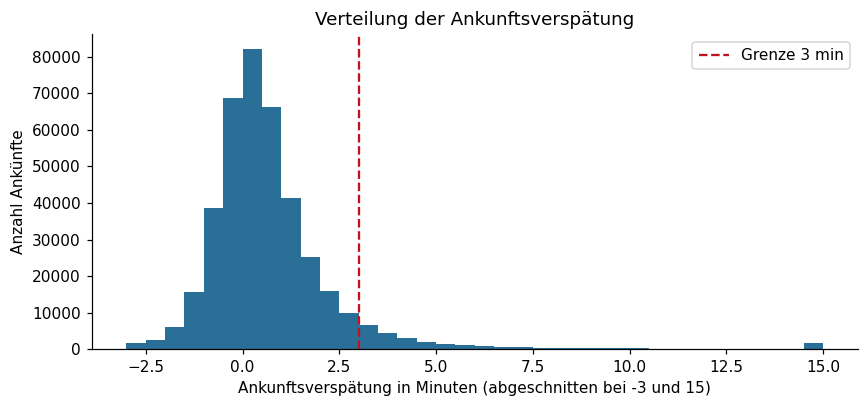

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(df["an_delay_min"].clip(-3, 15), bins=np.arange(-3, 15.5, 0.5), color="#2a6f97")
ax.axvline(config.LATE_THRESHOLD_MIN, color="#c1121f", ls="--", label="Grenze 3 min")
ax.set_xlabel("Ankunftsverspätung in Minuten (abgeschnitten bei -3 und 15)"); ax.set_ylabel("Anzahl Ankünfte")
ax.set_title("Verteilung der Ankunftsverspätung"); ax.legend()
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_histogramm_verspaetung.png", dpi=200); plt.show()

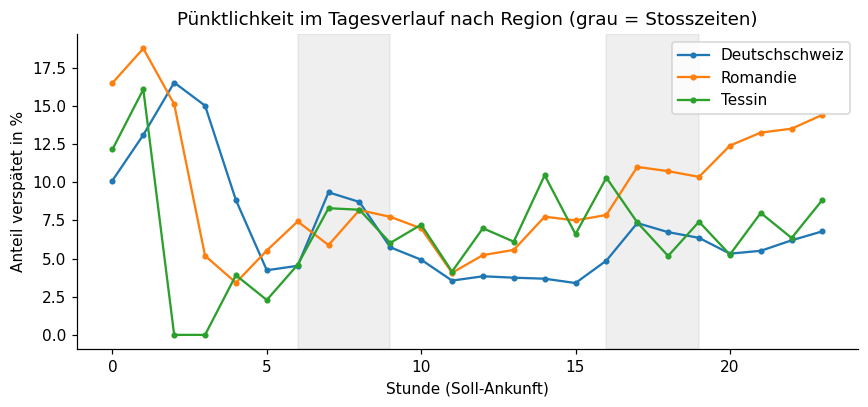

In [7]:
regionen = [r for r in ["Deutschschweiz", "Romandie", "Tessin"] if r in df["region"].unique()]
fig, ax = plt.subplots(figsize=(8, 3.8))
for r in regionen:
    s = df[df["region"] == r].groupby("stunde")["verspaetet"].mean()
    ax.plot(s.index, 100 * s.values, marker="o", ms=3, label=r)
for a, b in [(6, 9), (16, 19)]:
    ax.axvspan(a, b, color="grey", alpha=0.12)
ax.set_xlabel("Stunde (Soll-Ankunft)"); ax.set_ylabel("Anteil verspätet in %")
ax.set_title("Pünktlichkeit im Tagesverlauf nach Region (grau = Stosszeiten)"); ax.legend()
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_verspaetung_tagesverlauf.png", dpi=200); plt.show()

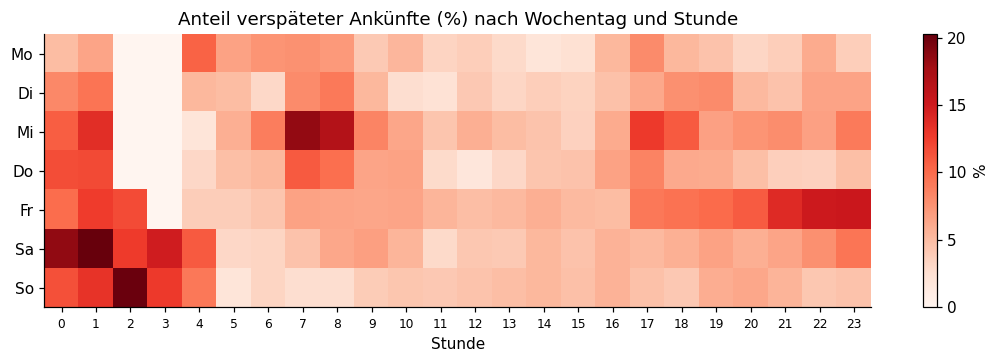

In [8]:
pivot = df.pivot_table(index="wochentag", columns="stunde", values="verspaetet", aggfunc="mean", observed=True) * 100
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(pivot.values, aspect="auto", cmap="Reds")
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, fontsize=8)
ax.set_xlabel("Stunde"); ax.set_title("Anteil verspäteter Ankünfte (%) nach Wochentag und Stunde")
fig.colorbar(im, ax=ax, label="%")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_heatmap_wochentag_stunde.png", dpi=200); plt.show()

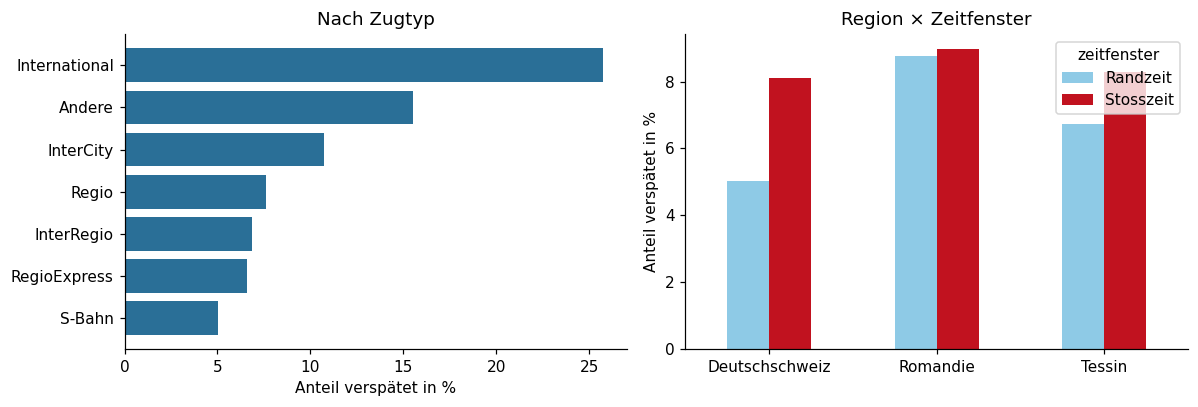

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
z = df.groupby("zugtyp_gruppe")["verspaetet"].mean().sort_values() * 100
axes[0].barh(z.index, z.values, color="#2a6f97"); axes[0].set_xlabel("Anteil verspätet in %"); axes[0].set_title("Nach Zugtyp")

grp = df.groupby(["region", "zeitfenster"])["verspaetet"].mean().unstack() * 100
grp = grp.loc[[r for r in regionen if r in grp.index]]
grp.plot(kind="bar", ax=axes[1], color=["#8ecae6", "#c1121f"], rot=0)
axes[1].set_ylabel("Anteil verspätet in %"); axes[1].set_xlabel(""); axes[1].set_title("Region × Zeitfenster")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_zugtyp_region_zeitfenster.png", dpi=200); plt.show()

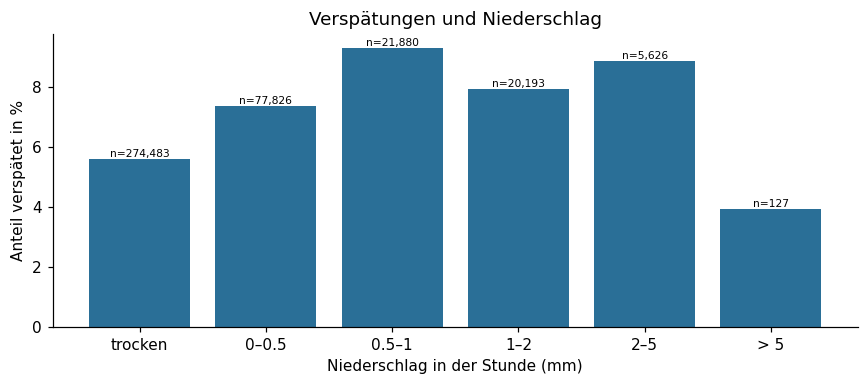

In [10]:
bins = [-0.01, 0.0, 0.5, 1, 2, 5, 100]
labels = ["trocken", "0–0.5", "0.5–1", "1–2", "2–5", "> 5"]
df["regen_klasse"] = pd.cut(df["niederschlag"].fillna(0), bins=bins, labels=labels)
r = df.groupby("regen_klasse", observed=True).agg(anteil=("verspaetet", "mean"), n=("verspaetet", "size"))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(r.index.astype(str), 100 * r["anteil"], color="#2a6f97")
for i, (a, n) in enumerate(zip(r["anteil"], r["n"])):
    ax.text(i, 100 * a, f"n={n:,}", ha="center", va="bottom", fontsize=7)
ax.set_xlabel("Niederschlag in der Stunde (mm)"); ax.set_ylabel("Anteil verspätet in %")
ax.set_title("Verspätungen und Niederschlag")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_niederschlag.png", dpi=200); plt.show()

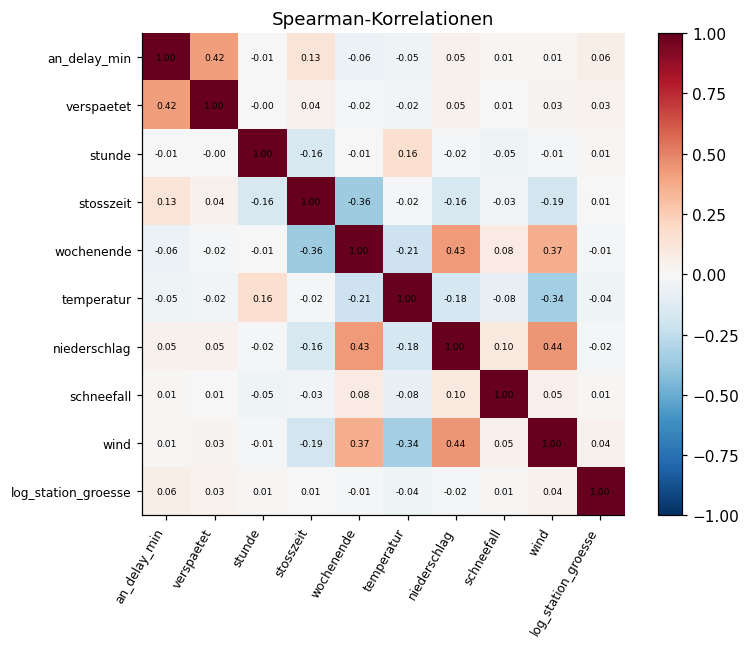

In [11]:
num = ["an_delay_min", "verspaetet", "stunde", "stosszeit", "wochenende", "temperatur",
       "niederschlag", "schneefall", "wind", "log_station_groesse"]
corr = df[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(num))); ax.set_yticklabels(num, fontsize=8)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax); ax.set_title("Spearman-Korrelationen")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "03_korrelationen.png", dpi=200); plt.show()

## 3. Erkenntnisse aus der EDA
*(Stand: echte Daten 14.–27.10.2026 ohne 19.10., 400'135 Ankünfte an den 100 grössten Bahnhöfen)*
- **Verteilung:** stark rechtsschief. Median 0,4 min, 93,7 % der Ankünfte liegen unter 3 min. Insgesamt sind **6,3 %** verspätet (≥ 3 min) → unausgeglichene Klassen, wichtig für das Modell.
- **Tagesverlauf / Stosszeiten:** In der Deutschschweiz gibt es klare Spitzen in der Morgen- und Abendstosszeit (Stosszeit 8,1 % vs. Randzeit 5,0 %). In der **Romandie steigt der Anteil dagegen über den Tag fast stetig an** (ca. 4 % um 11 Uhr → über 14 % um 23 Uhr); dort gibt es kaum einen Unterschied zwischen Stoss- und Randzeit (9,0 % vs. 8,8 %). Hohe Werte nachts (0–3 Uhr) beruhen auf wenigen Fahrten (Wochenend-Nachtverkehr).
- **Wochentag:** Mittwoch (8,4 %) und Freitag (7,8 %) am schlechtesten, Montag (4,9 %) am besten. Bei nur 2 Wochen sind das evtl. Einzelereignisse.
- **Regionen:** Romandie 8,8 %, Tessin 7,1 %, Deutschschweiz 5,8 %. Die mittlere Verspätung ist fast gleich (0,75–0,89 min), der Unterschied liegt in den Ausreissern.
- **Zugtyp:** internationale Züge 25,8 %, InterCity 10,7 %, S-Bahn nur 5,0 %. Lange Laufwege sammeln Verspätung an.
- **Wetter:** bei Regen (≥ 0,1 mm/h) 7,8 % vs. 5,6 % ohne Regen. Schnee gab es im Oktober praktisch nicht.
